# Pandas - Topic 09 - Data Manipulation Part 2¶


## Topic Objectives

In this unit you will learn techniques that will assist you when you come to cleaning data sets.

- Replace data in a DataFrame
- Change data type
- Manage duplicated data


## Import Package for Learning

In [61]:
import numpy as np
import pandas as pd

## Pandas - Topic 09 - Data Manipulation Part 2


In this notebook we will cover

- how to replace data in your DataFrame using .replace()
- how to change the data type with .astype()
- how to manage duplicated data with .duplicated() and .drop_duplicates()

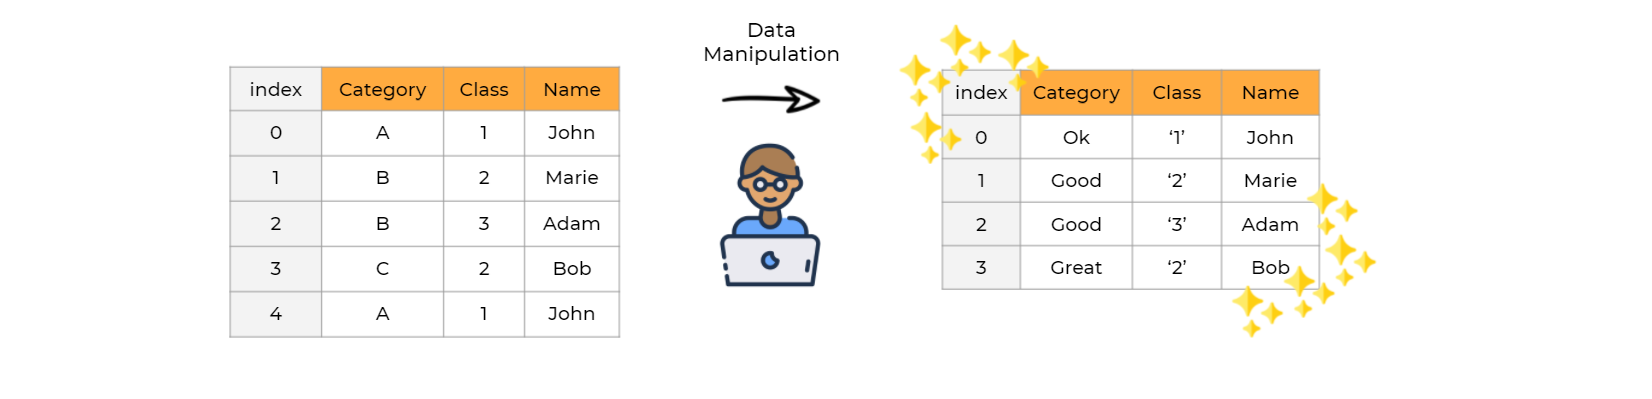

Consider the dataset from the previous unit

In [62]:
df = pd.DataFrame(data={'Col1':np.random.randint(low=0,high=50,size=10),
                        'Col2':np.random.randn(10),
                        'Col3':['A','B','C','A','A','C','D','B','A','A'],
                        'Col4':np.random.choice([True, False],size=10),
                        'Col5':np.random.randint(low=1,high=4,size=10),
                        'Col6':['X','X','Y','Z','Z','Z','Y','X','Z','Z']},
                  index=pd.date_range(start='01/01/2021', periods=10, freq='M'))
df

C:\Users\zainab\AppData\Local\Temp\ipykernel_21544\2730972482.py:7: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  index=pd.date_range(start='01/01/2021', periods=10, freq='M'))


,Col1,Col2,Col3,Col4,Col5,Col6
2021-01-31,47,-2.259944,A,False,1,X
2021-02-28,4,0.014335,B,True,2,X
2021-03-31,2,0.440102,C,False,2,Y
2021-04-30,6,-0.340437,A,True,3,Z
2021-05-31,19,-0.753507,A,False,2,Z
2021-06-30,27,0.539950,C,False,2,Z
2021-07-31,6,2.044506,D,False,1,Y
2021-08-31,19,-0.476736,B,False,2,X
2021-09-30,21,-0.888246,A,False,1,Z
2021-10-31,49,-0.940247,A,True,3,Z


Replace Values

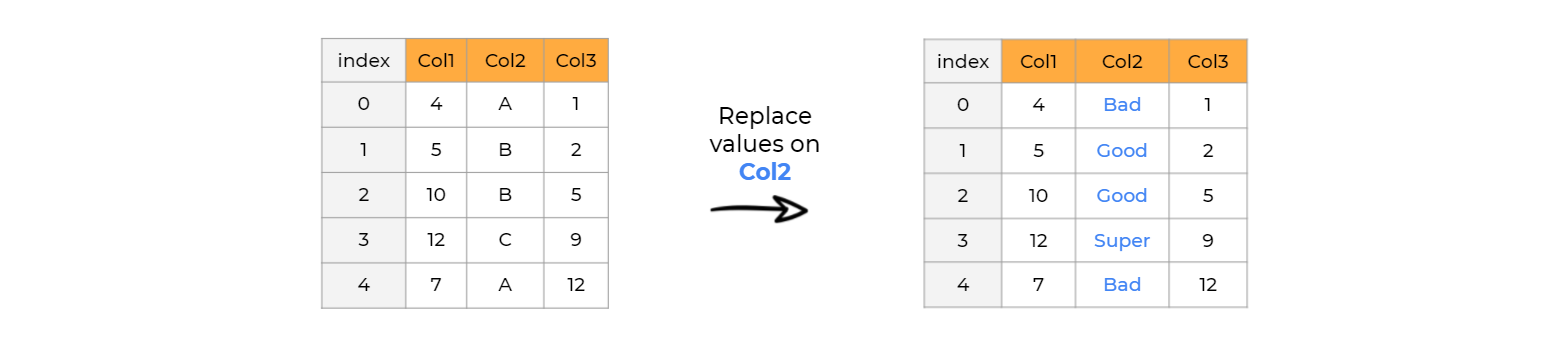

- You can replace values in your dataframe using .replace(). You can parse a Python dictionary that will map the values in the 'to_replace' argument
  - For teaching purposes, first, we create a Python dictionary that maps the character keys to human-readable category values. We will map Col3 values to numbers
  - The function documentation can be found [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.replace.html)

In [63]:
map_dict = {'A': 'Nice', 'B': 'Super', 'C':'Amazing', 'D':'Incredible'}
map_dict

{'A': 'Nice', 'B': 'Super', 'C': 'Amazing', 'D': 'Incredible'}

We now parse this dictionary

- You can do that in one line. We broke it into two lines for a better learning experience

- Remember that in the example below, we overwrote the existing DataFrame since we set inplace=True

In [64]:
df['Col3'].replace(to_replace=map_dict, inplace=True)
df

C:\Users\zainab\AppData\Local\Temp\ipykernel_21544\4262300524.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Col3'].replace(to_replace=map_dict, inplace=True)


,Col1,Col2,Col3,Col4,Col5,Col6
2021-01-31,47,-2.259944,Nice,False,1,X
2021-02-28,4,0.014335,Super,True,2,X
2021-03-31,2,0.440102,Amazing,False,2,Y
2021-04-30,6,-0.340437,Nice,True,3,Z
2021-05-31,19,-0.753507,Nice,False,2,Z
2021-06-30,27,0.539950,Amazing,False,2,Z
2021-07-31,6,2.044506,Incredible,False,1,Y
2021-08-31,19,-0.476736,Super,False,2,X
2021-09-30,21,-0.888246,Nice,False,1,Z
2021-10-31,49,-0.940247,Nice,True,3,Z


In [65]:
df['Col3'] = df['Col3'].replace(to_replace=map_dict)
df

,Col1,Col2,Col3,Col4,Col5,Col6
2021-01-31,47,-2.259944,Nice,False,1,X
2021-02-28,4,0.014335,Super,True,2,X
2021-03-31,2,0.440102,Amazing,False,2,Y
2021-04-30,6,-0.340437,Nice,True,3,Z
2021-05-31,19,-0.753507,Nice,False,2,Z
2021-06-30,27,0.539950,Amazing,False,2,Z
2021-07-31,6,2.044506,Incredible,False,1,Y
2021-08-31,19,-0.476736,Super,False,2,X
2021-09-30,21,-0.888246,Nice,False,1,Z
2021-10-31,49,-0.940247,Nice,True,3,Z


You can replace numbers with a category. The example below replaces the categories from Col6 to numbers

In [66]:
df["Col6"] = df['Col6'].replace(to_replace={'X': 1, 'Y': 20, 'Z':4000})
df

C:\Users\zainab\AppData\Local\Temp\ipykernel_21544\1083988565.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Col6"] = df['Col6'].replace(to_replace={'X': 1, 'Y': 20, 'Z':4000})


,Col1,Col2,Col3,Col4,Col5,Col6
2021-01-31,47,-2.259944,Nice,False,1,1
2021-02-28,4,0.014335,Super,True,2,1
2021-03-31,2,0.440102,Amazing,False,2,20
2021-04-30,6,-0.340437,Nice,True,3,4000
2021-05-31,19,-0.753507,Nice,False,2,4000
2021-06-30,27,0.539950,Amazing,False,2,4000
2021-07-31,6,2.044506,Incredible,False,1,20
2021-08-31,19,-0.476736,Super,False,2,1
2021-09-30,21,-0.888246,Nice,False,1,4000
2021-10-31,49,-0.940247,Nice,True,3,4000


You can check the columns' data types and note: Col6 is not categorical (object) anymore.

In [67]:
df.dtypes

Col1      int32
Col2    float64
Col3     object
Col4       bool
Col5      int32
Col6      int64
dtype: object

### Change data type

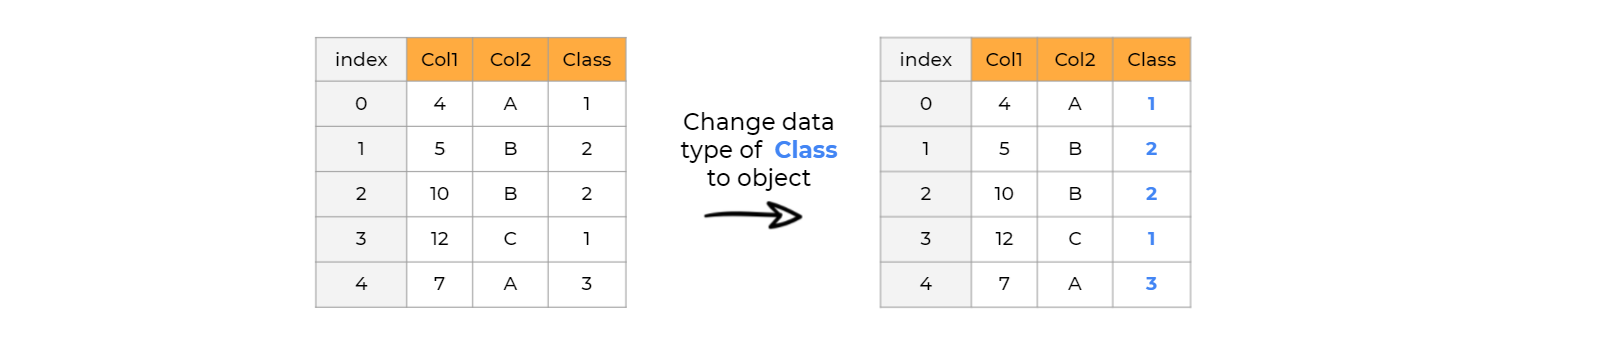

You can also change the data format using the .astype() method and parsing in a dictionary containing the new datatype for a given column. The documentation can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.astype.html)

- Let's recap df using .head(3) - since you don't need to see all of the rows for that

In [68]:
df.head(3)

,Col1,Col2,Col3,Col4,Col5,Col6
2021-01-31,47,-2.259944,Nice,False,1,1
2021-02-28,4,0.014335,Super,True,2,1
2021-03-31,2,0.440102,Amazing,False,2,20


You notice that the data type of Col5 is integer. However, you were informed that the content should be categorical. Imagine if the meaning of this variable is 'quality' and ranges from 1 to 3, where 1 is low quality and 3 is good quality.

- Now you want to convert Col5 to categorical/object, so you can properly conduct your data analysis
- .astype() doesn't have an 'inplace' argument, so you can re-assign the DataFrame content like:

In [69]:
df = df.astype({"Col5":"object"})
df

,Col1,Col2,Col3,Col4,Col5,Col6
2021-01-31,47,-2.259944,Nice,False,1,1
2021-02-28,4,0.014335,Super,True,2,1
2021-03-31,2,0.440102,Amazing,False,2,20
2021-04-30,6,-0.340437,Nice,True,3,4000
2021-05-31,19,-0.753507,Nice,False,2,4000
2021-06-30,27,0.539950,Amazing,False,2,4000
2021-07-31,6,2.044506,Incredible,False,1,20
2021-08-31,19,-0.476736,Super,False,2,1
2021-09-30,21,-0.888246,Nice,False,1,4000
2021-10-31,49,-0.940247,Nice,True,3,4000


When you check the data type of Col5, you will see that it is an object

In [70]:
df.dtypes

Col1      int32
Col2    float64
Col3     object
Col4       bool
Col5     object
Col6      int64
dtype: object

Managing duplicated data¶

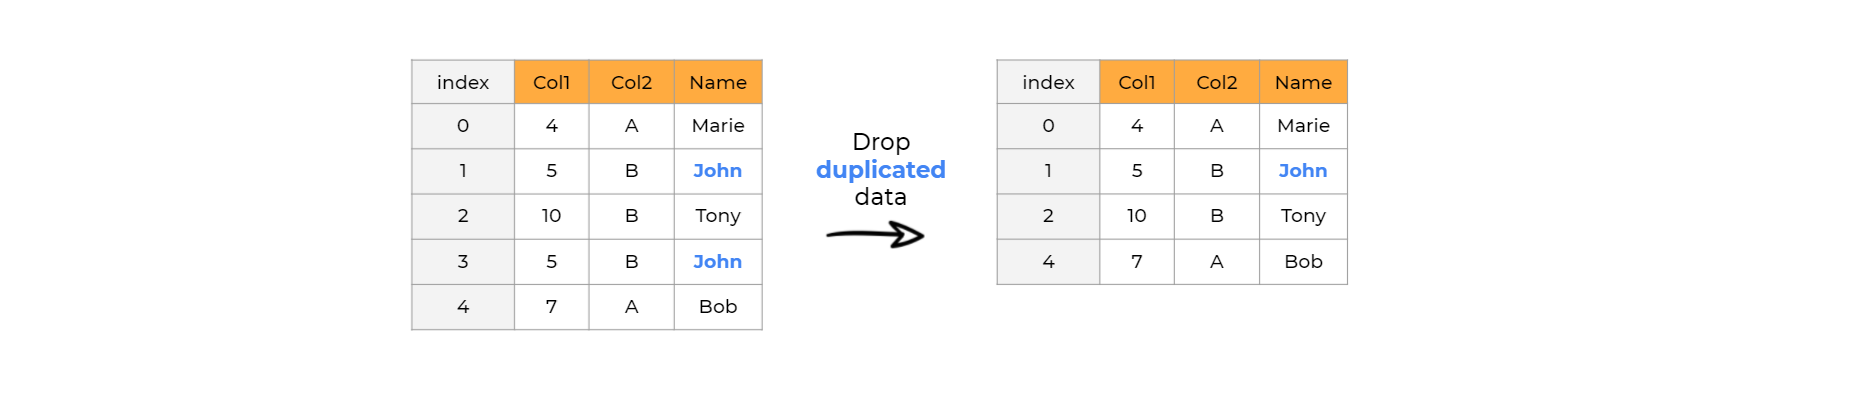

- You can check and drop duplicated data. Consider the DataFrame below

In [71]:
df = pd.DataFrame(data={'Name':['John','Marie','Joseph','John','Willian','Marie'],
                        'CustomerRate':[1,2,2,4,3,3]}
                  )
df

,Name,CustomerRate
0,John,1
1,Marie,2
2,Joseph,2
3,John,4
4,Willian,3
5,Marie,3


It is decided for this DataFrame that each Name should be unique. For some reason, John and Marie are repeated, even though the CustomerRate is different.

However, in this case, it should have only 1 John and only 1 Marie.

- Use .duplicated() to grab rows which are repeated in the column you are interested in.
- Use the subset argument to only consider certain columns for identifying duplicates. By default, it uses all columns to check for duplication, but in this case, we are interested only in 'Name'. The documentation is [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html)

In [72]:
df.duplicated(subset=['Name'])

0    False
1    False
2    False
3     True
4    False
5     True
dtype: bool

The result is a boolean series, so we parse that to the DataFrame to get the rows themselves.

- We can see that indexes 3 and 5 are duplicated, which happens to be John and Marie
- By default, when finding a duplicate, it doesn't mark as duplicate the first occurrence. In the example, it says index 0 (John) is not duplicated, but index 3 is a duplicate

In [73]:
df[df.duplicated(subset=['Name'])]

,Name,CustomerRate
3,John,4
5,Marie,3


- But maybe you are interested to see all data marked as duplicated, so you can decide which to remove.
  - In the example, the row with the index of 0 is the duplicate of 3, not the opposite. In this case, set the 'keep' argument as False to see all that are duplicates

In [74]:
df[df.duplicated(subset=['Name'], keep=False)]

,Name,CustomerRate
0,John,1
1,Marie,2
3,John,4
5,Marie,3


You can drop duplicate rows with the method .drop_duplicates(); the documentation is [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html)
Note we set subset='Name' to find duplicates in the column: Name
And we set inplace=True, so we overwrite the DataFrame

In [75]:
df.drop_duplicates(subset=['Name'], inplace=True)
df

,Name,CustomerRate
0,John,1
1,Marie,2
2,Joseph,2
4,Willian,3


**PRACTICE:** Consider the dataset which contains information on transactions made by customers through an online retail platform. The dataset includes data on the products that were purchased, the quantity of each product, the date and time of each transaction, the price of each product, the unique identifier for each customer who made a purchase, and the country where each customer is located.

- We have the information that the pair InvoiceNo, StockCode and CustomerID should be unique. For some fictitious reason, a given customer can buy only a given product once per invoice.

In [76]:
df_practice = pd.read_csv("Online_retail.csv")
df_practice

,index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...,...
541904,541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


You should show all data marked as duplicated.

In [77]:
df_practice[df_practice.duplicated(subset=['InvoiceNo', 'StockCode', 'CustomerID'])] 

,index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
125,125,536381,71270,PHOTO CLIP LINE,3,12/1/2010 9:41,1.25,15311.0,United Kingdom
498,498,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,1,12/1/2010 11:45,6.35,17908.0,United Kingdom
502,502,536409,85116,BLACK CANDELABRA T-LIGHT HOLDER,5,12/1/2010 11:45,2.10,17908.0,United Kingdom
517,517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
525,525,536409,90199C,5 STRAND GLASS NECKLACE CRYSTAL,2,12/1/2010 11:45,6.35,17908.0,United Kingdom
...,...,...,...,...,...,...,...,...,...
541692,541692,581538,22992,REVOLVER WOODEN RULER,1,12/9/2011 11:34,1.95,14446.0,United Kingdom
541697,541697,581538,21194,PINK HONEYCOMB PAPER FAN,1,12/9/2011 11:34,0.65,14446.0,United Kingdom
541698,541698,581538,35004B,SET OF 3 BLACK FLYING DUCKS,1,12/9/2011 11:34,5.45,14446.0,United Kingdom
541699,541699,581538,22694,WICKER STAR,1,12/9/2011 11:34,2.10,14446.0,United Kingdom


Then, drop the duplicates.

In [78]:
df_practice.drop_duplicates(subset=["InvoiceNo", "StockCode", "CustomerID"], inplace=True) 

 

df_practice 

,index,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...,...
541904,541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
